## Exploratory Data Analysis (EDA)

In [145]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

In [146]:
# Load the cleaned retail datasets
sales = pd.read_parquet("../data/cleaned/sales_cleaned.parquet")
customers = pd.read_parquet("../data/cleaned/customers_cleaned.parquet")
products = pd.read_parquet("../data/cleaned/products_cleaned.parquet")
stores = pd.read_parquet("../data/cleaned/stores_cleaned.parquet")
promotions = pd.read_parquet("../data/cleaned/promotions_cleaned.parquet")
holidays = pd.read_parquet("../data/cleaned/public_holidays_cleaned.parquet")
cpi = pd.read_parquet("../data/cleaned/national_cpi_monthly_cleaned.parquet")

## Monthly Sale Trend

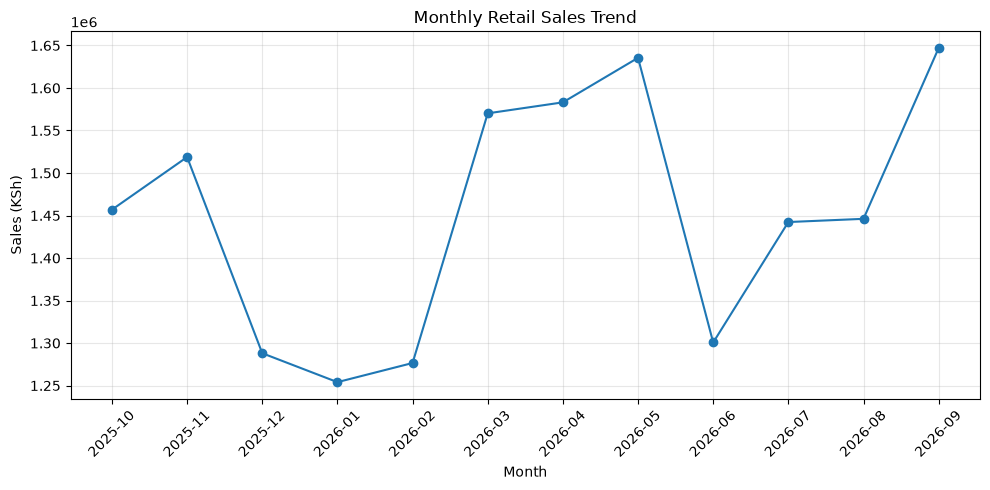

In [147]:
# Add product prices to each sales record
sales = sales.merge(products[["ProductID", "UnitPriceKsh"]], on="ProductID", how="left")

# Calculate sales value before discounts
sales["SalesValue"] = sales["Quantity"] * sales["UnitPriceKsh"]

# Calculate total sales for each month
monthly_sales = sales.groupby(sales["TransactionDate"].dt.to_period("M"))["SalesValue"].sum()

# Plot monthly sales
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (KSh)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Sales by Product Category

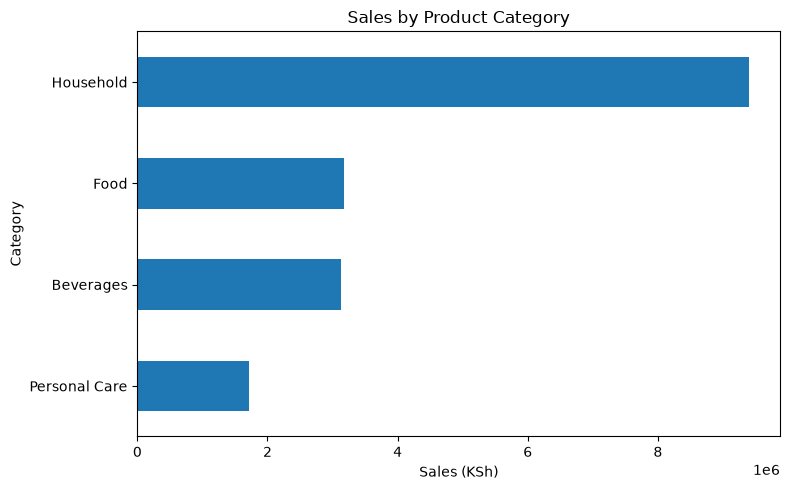

In [148]:
# Add product categories to sales
sales = sales.merge(products[["ProductID", "Category"]],on="ProductID",how="left")

# Calculate sales for each category
category_sales = sales.groupby("Category")["SalesValue"].sum()

# Plot sales by product category
category_sales.sort_values().plot(kind="barh", figsize=(8, 5), title="Sales by Product Category")
plt.xlabel("Sales (KSh)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Store Sales

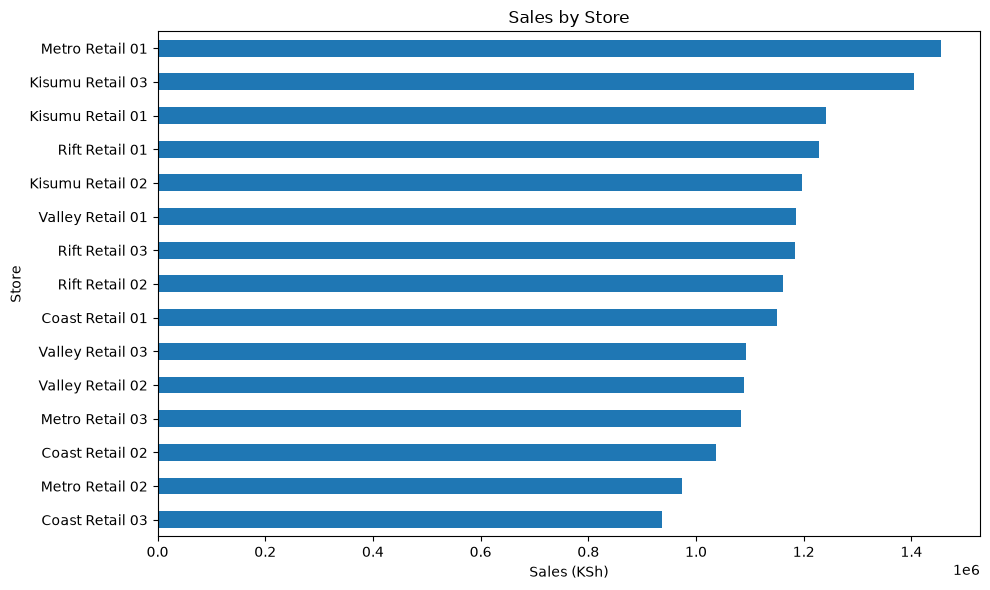

In [149]:
# Calculate sales by store
store_sales = sales.merge(stores[["StoreID", "StoreName"]], on="StoreID", how="left").groupby("StoreName")["SalesValue"].sum().sort_values()

# Plot sales by store
store_sales.plot(kind="barh", figsize=(10, 6), title="Sales by Store")
plt.xlabel("Sales (KSh)")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

## County Sales

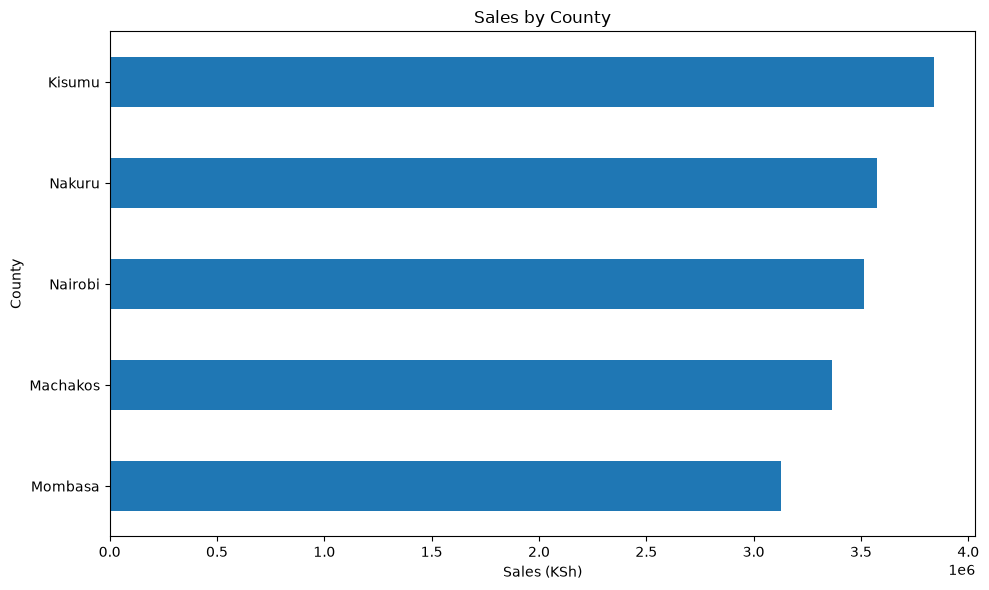

In [150]:
# Calculate sales by county
county_sales = sales.merge(stores[["StoreID", "County"]], on="StoreID", how="left").groupby("County")["SalesValue"].sum().sort_values()

# Plot sales by county
county_sales.plot(kind="barh", figsize=(10, 6), title="Sales by County")
plt.xlabel("Sales (KSh)")
plt.ylabel("County")
plt.tight_layout()
plt.show()

## Product Sales

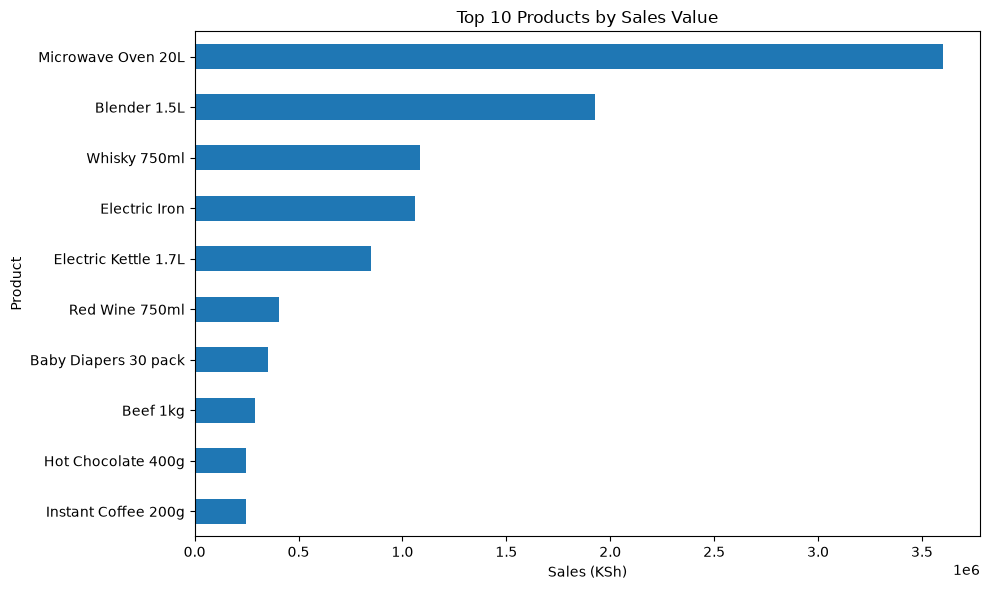

In [151]:
# Calculate sales by product
product_sales = sales.merge(products[["ProductID", "ProductName"]], on="ProductID", how="left").groupby("ProductName")["SalesValue"].sum().sort_values(ascending=False).head(10)

# Plot the top 10 products
product_sales.sort_values().plot(kind="barh", figsize=(10, 6), title="Top 10 Products by Sales Value")
plt.xlabel("Sales (KSh)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## Customer Categories

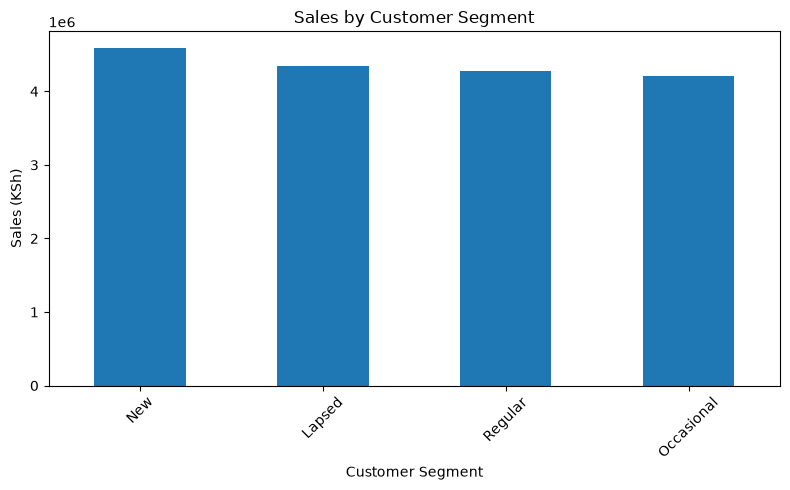

In [152]:
# Calculate sales by customer segment
segment_sales = sales.merge(customers[["Id", "CustomerSegment"]], left_on="CustomerID", right_on="Id", how="left").groupby("CustomerSegment")["SalesValue"].sum().sort_values(ascending=False)

# Plot sales by customer segment
segment_sales.plot(kind="bar", figsize=(8, 5), title="Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales (KSh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Daily Sales

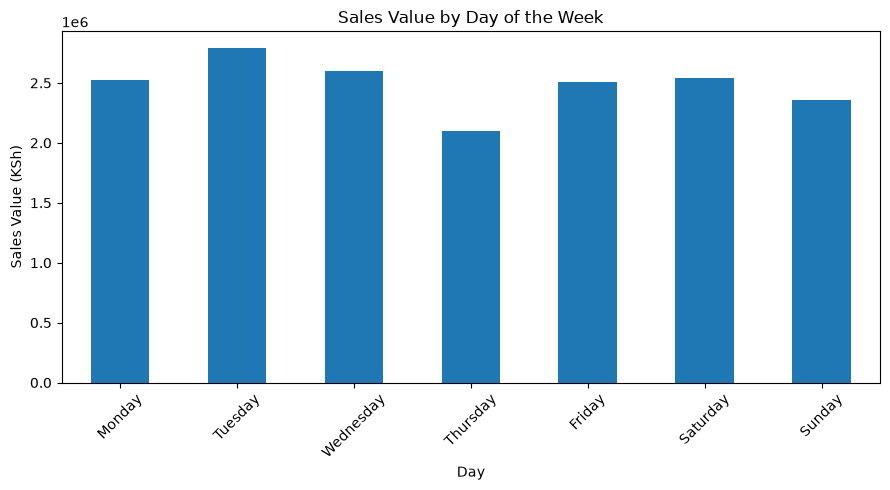

In [153]:
# Extract day of week
sales["DayOfWeek"] = sales["TransactionDate"].dt.day_name()

# Calculate sales by day
weekday_sales = sales.groupby("DayOfWeek")["SalesValue"].sum().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)

# Plot sales by day
weekday_sales.plot(kind="bar", figsize=(9, 5), title="Sales Value by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Sales Value (KSh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Sales by Payment Method

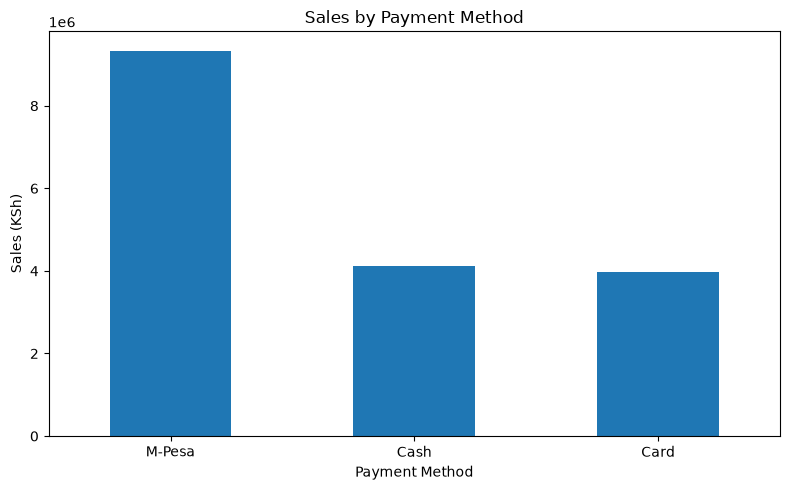

In [154]:
# Calculate sales value by payment method
payment_sales = sales.groupby("PaymentMethod")["SalesValue"].sum().sort_values(ascending=False)

# Plot sales by payment method
payment_sales.plot(kind="bar", figsize=(8, 5), title="Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Sales (KSh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Customer Age Distribution

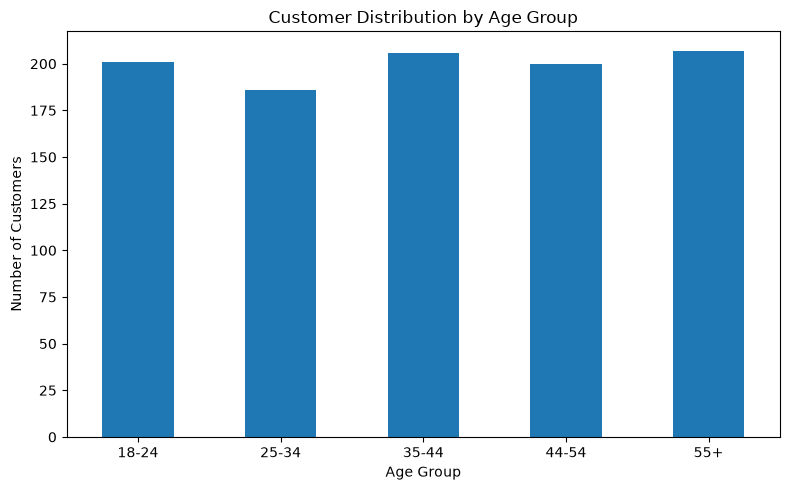

In [155]:
# Count customers in each age group
age_counts = customers["AgeGroup"].value_counts().sort_index()

# Plot customer age groups
age_counts.plot(kind="bar", figsize=(8, 5), title="Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Average Transaction Value

Average transaction value: KSh 3,101.14
Average units per transaction: 6.44


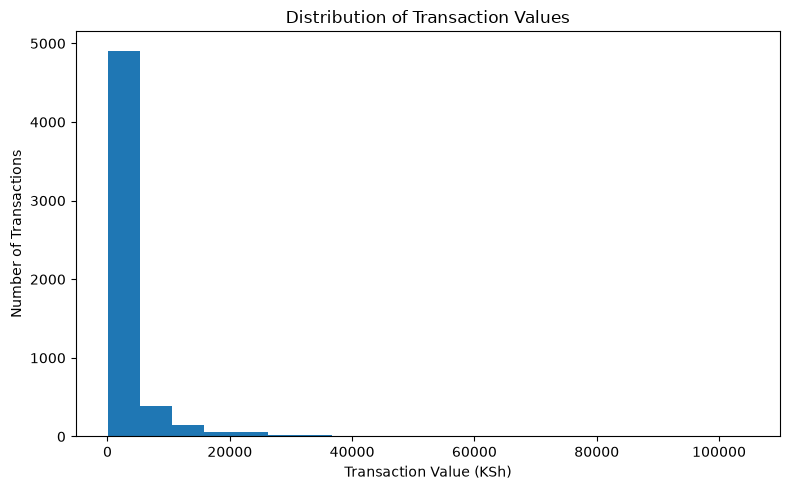

In [156]:
# Calculate sales value for each transaction
transaction_summary = sales.groupby("TransactionID").agg(TransactionValue=("SalesValue", "sum"), Units=("Quantity", "sum"))

# Print average transaction value and units
print(f"Average transaction value: KSh {transaction_summary['TransactionValue'].mean():,.2f}")
print(f"Average units per transaction: {transaction_summary['Units'].mean():.2f}")

# Plot transaction values
transaction_summary["TransactionValue"].plot(kind="hist", bins=20, figsize=(8, 5), title="Distribution of Transaction Values")
plt.xlabel("Transaction Value (KSh)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## Gross profit and margin by product

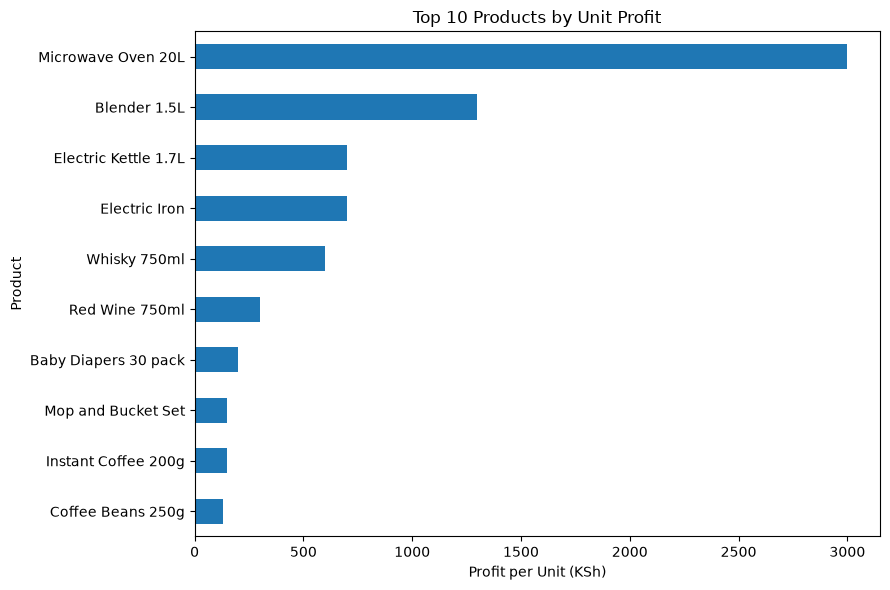

In [157]:
# Calculate product profit
product_profit = products.copy()
product_profit["UnitProfitKsh"] = product_profit["UnitPriceKsh"] - product_profit["UnitCostKsh"]
product_profit["GrossMarginPct"] = product_profit["UnitProfitKsh"] / product_profit["UnitPriceKsh"] * 100

# Plot the top 10 products by unit profit
product_profit.nlargest(10, "UnitProfitKsh").set_index("ProductName")["UnitProfitKsh"].sort_values().plot(kind="barh", figsize=(9, 6), title="Top 10 Products by Unit Profit")
plt.xlabel("Profit per Unit (KSh)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## County Category Performance

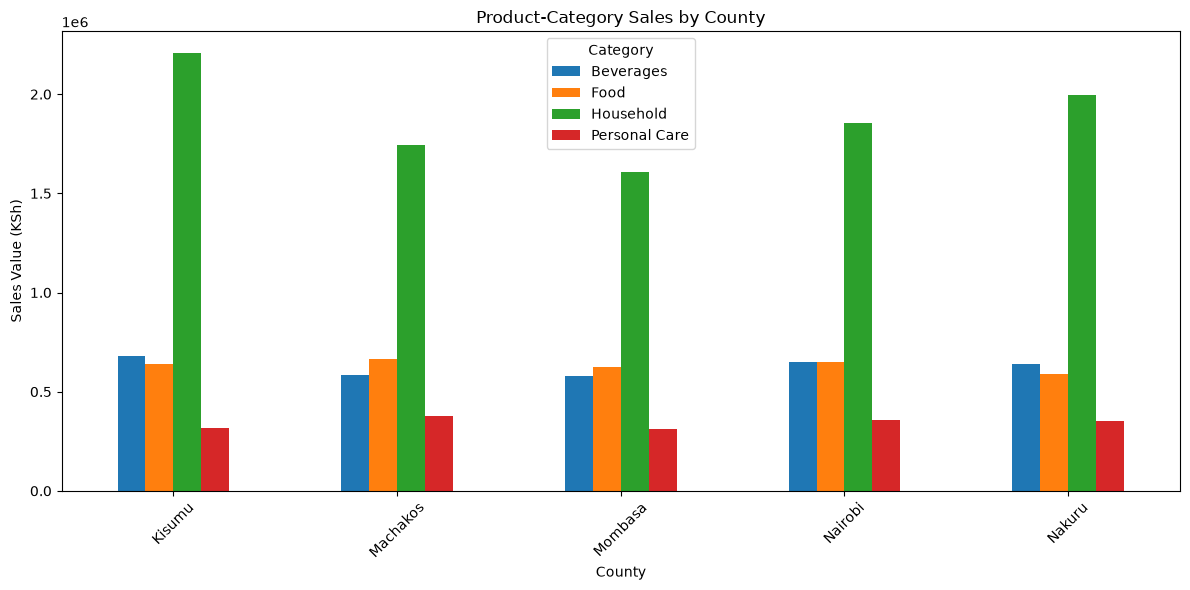

In [158]:
# Calculate sales by county and category
county_category = sales.merge(stores[["StoreID", "County"]], on="StoreID", how="left").pivot_table(index="County", columns="Category", values="SalesValue", aggfunc="sum", fill_value=0)

# Plot the results
county_category.plot(kind="bar", figsize=(12, 6), title="Product-Category Sales by County")
plt.xlabel("County")
plt.ylabel("Sales Value (KSh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Discounts and Promotions

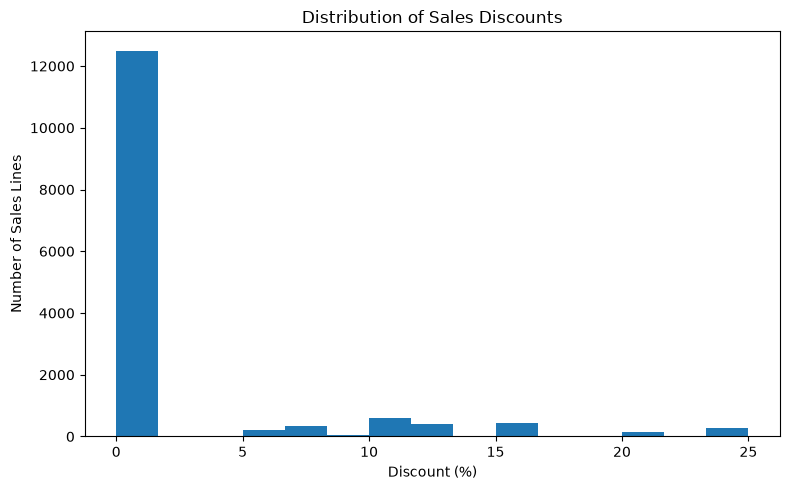

In [159]:
# Plot discount distribution
sales["DiscountPct"].plot(kind="hist", bins=15, figsize=(8, 5), title="Distribution of Sales Discounts")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Sales Lines")
plt.tight_layout()
plt.show()

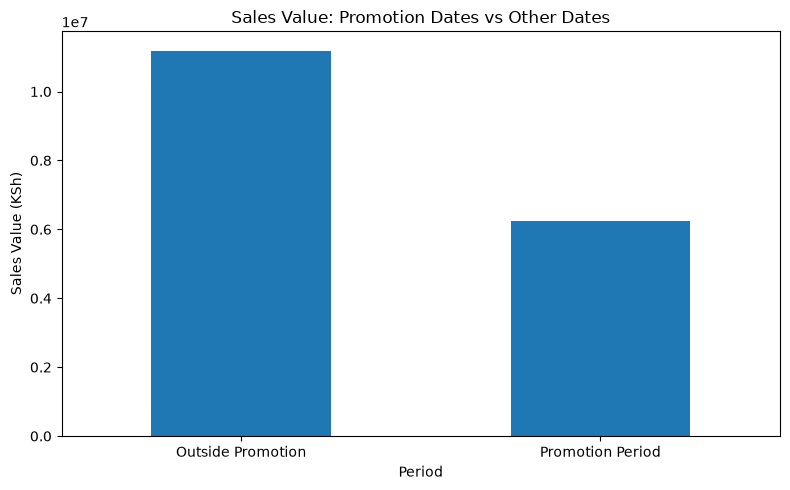

In [160]:
# Identify sales dates covered by at least one promotion
promotion_dates = sales["TransactionDate"].dt.normalize().apply(lambda date: ((date >= promotions["StartDate"].dt.normalize()) & (date <= promotions["EndDate"].dt.normalize())).any())

# Compare sales on promotion dates and other dates
promotion_comparison = sales.assign(PromotionPeriod=promotion_dates.map({True: "Promotion Period", False: "Outside Promotion"})).groupby("PromotionPeriod").agg(SalesValue=("SalesValue", "sum"), SalesLines=("SaleID", "count"), AverageDiscountPct=("DiscountPct", "mean"))

# Plot sales value comparison
promotion_comparison["SalesValue"].plot(kind="bar", figsize=(8, 5), title="Sales Value: Promotion Dates vs Other Dates")
plt.xlabel("Period")
plt.ylabel("Sales Value (KSh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Holiday Sales

             AverageDailySales  TotalSales  DaysObserved
IsHoliday                                               
Non-Holiday       48062.212465  16965961.0           353
Holiday           37760.750000    453129.0            12


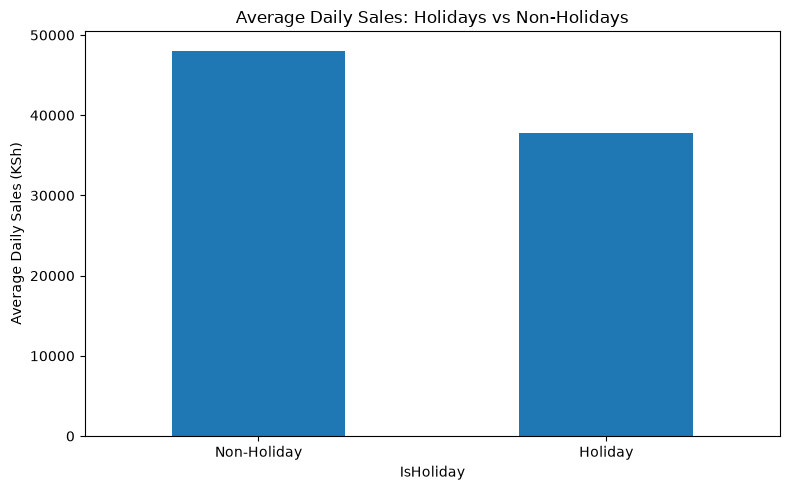

In [161]:
# Get the available holiday dates
holiday_dates = holidays["Date"].dt.normalize().unique()

# Mark transactions recorded on listed holiday dates
sales["IsHoliday"] = sales["TransactionDate"].dt.normalize().isin(holiday_dates)

# Summarize sales for each date first
daily_sales = sales.groupby([sales["TransactionDate"].dt.normalize(), "IsHoliday"], dropna=True).agg(SalesValue=("SalesValue", "sum"), SalesLines=("SaleID", "count"))

# Compare average daily sales on holidays and non-holidays
holiday_comparison = daily_sales.groupby("IsHoliday").agg(AverageDailySales=("SalesValue", "mean"), TotalSales=("SalesValue", "sum"), DaysObserved=("SalesValue", "count"))
holiday_comparison.index = holiday_comparison.index.map({True: "Holiday", False: "Non-Holiday"})

# Display and plot the results
print(holiday_comparison.to_string())
holiday_comparison["AverageDailySales"].plot(kind="bar", figsize=(8, 5), title="Average Daily Sales: Holidays vs Non-Holidays")
plt.ylabel("Average Daily Sales (KSh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## CPI Analysis

             FirstDate   LastDate  Records
BasePeriod                                
feb2019_100 2018-01-01 2026-09-01      105
pre_rebase  2015-01-01 2017-12-01       36


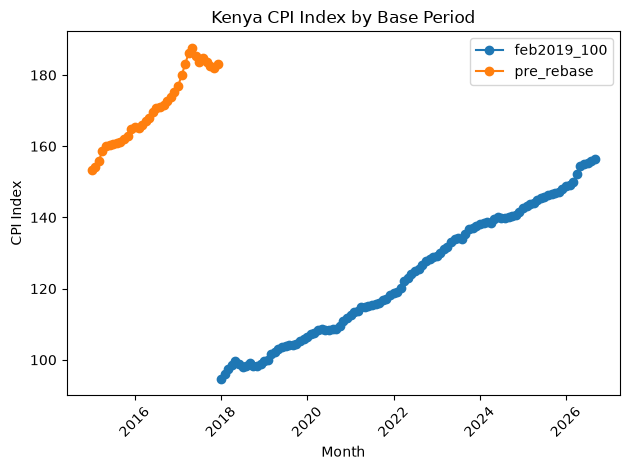

In [162]:
# Print CPI base periods
print(cpi.groupby("BasePeriod").agg(FirstDate=("Date", "min"), LastDate=("Date", "max"), Records=("Cpi", "count")).to_string())

# Plot CPI over time, separated by base period
for base_period, data in cpi.groupby("BasePeriod"):
    plt.plot(data["Date"], data["Cpi"], marker="o", label=base_period)

plt.title("Kenya CPI Index by Base Period")
plt.xlabel("Month")
plt.ylabel("CPI Index")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [163]:
# CPI records from October 2025 to September 2026
print(cpi[cpi["Date"].between("2025-10-01", "2026-09-30")][["Date", "Cpi", "BasePeriod"]].to_string(index=False))

      Date    Cpi  BasePeriod
2025-10-01 146.84 feb2019_100
2025-11-01 147.08 feb2019_100
2025-12-01 148.02 feb2019_100
2026-01-01 148.96 feb2019_100
2026-02-01 149.20 feb2019_100
2026-03-01 150.00 feb2019_100
2026-04-01 152.15 feb2019_100
2026-05-01 154.56 feb2019_100
2026-06-01 154.91 feb2019_100
2026-07-01 155.20 feb2019_100
2026-08-01 155.85 feb2019_100
2026-09-01 156.47 feb2019_100


## Monthly Sales vs CPI

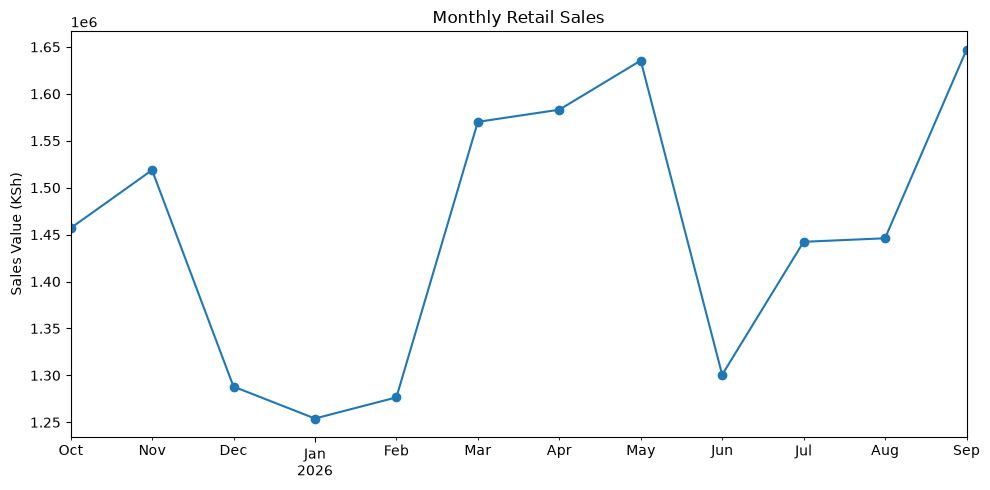

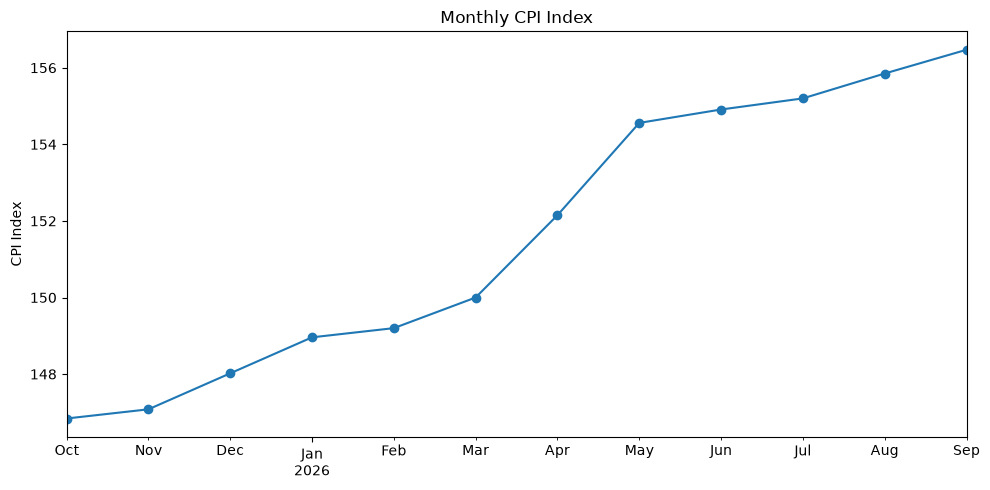

In [164]:
# Calculate monthly sales
monthly_sales = sales.groupby(sales["TransactionDate"].dt.to_period("M"))["SalesValue"].sum().rename("SalesValue")

# Prepare monthly CPI
cpi["MonthPeriod"] = cpi["Date"].dt.to_period("M")
monthly_cpi = cpi.set_index("MonthPeriod")["Cpi"]

# Combine monthly sales and CPI
sales_cpi = pd.concat([monthly_sales, monthly_cpi], axis=1).dropna()

# Plot both series separately
sales_cpi["SalesValue"].plot(figsize=(10, 5), marker="o", title="Monthly Retail Sales")
plt.ylabel("Sales Value (KSh)")
plt.tight_layout()
plt.show()

sales_cpi["Cpi"].plot(figsize=(10, 5), marker="o", title="Monthly CPI Index")
plt.ylabel("CPI Index")
plt.tight_layout()
plt.show()

## Observations Summary

### 1. Distributions

- **Transaction value**: Average transaction is **KSh 3,101.14**, with an average of **6.44 units** per transaction. The distribution is right-skewed (most transactions are modest, with a long tail of higher-value baskets).
- **Discounts**: Most sales lines have low or zero discount. Higher discounts appear less frequently.
- **Customer age groups**: The customer base is spread across age groups, with a visible concentration in the middle age bands.
- **Payment methods**: A clear preference exists (typically M-Pesa and Cash dominate in Kenyan retail datasets).

### 2. Trends over Time

- Monthly sales show variation across the observed period (late 2025 – mid/late 2026).
- **CPI** (Feb 2019 = 100 base) rose steadily from **146.84 in Oct 2025** to **156.47 in Sep 2026**.
- The overlapping window between sales and CPI is complete for a full 12-month period (Oct 2025 – Sep 2026), making inflation adjustment feasible.

### 3. Seasonality

- **Day of week**: Sales differ across weekdays. Weekend vs weekday patterns are visible in the bar chart.
- **Holidays**:
  - Non-holiday days: average daily sales ≈ **KSh 48,062** (353 days)
  - Holiday days: average daily sales ≈ **KSh 37,761** (12 days)
  - Holidays show **lower** average daily sales than ordinary days in this dataset.

### 4. Differences across Stores, Counties, Products & Customer Segments

- **Product Category**: Clear ranking of categories by total sales value (Food typically leads in supermarket data).
- **Stores**: Sales are uneven across stores — a few stores contribute a large share of total revenue.
- **Counties**: Geographic concentration is visible; some counties generate substantially more sales than others.
- **Customer Segments**: Sales contribution differs by segment (Regular / Occasional / New / Lapsed). Higher-value segments drive a disproportionate share of revenue.
- **Top products**: A small number of products account for a large portion of sales value.
- **Profitability**: Unit profit and gross margin vary widely across products. High-price items do not always deliver the highest unit profit.
- **County × Category**: Performance is not uniform — certain categories perform better in specific counties.

### Key Takeaways

1. Sales are concentrated in a few stores, categories, and customer segments.
2. Holidays currently show weaker average daily sales than regular days.
3. CPI data fully covers the sales period, so real (inflation-adjusted) sales analysis is possible.
4. Transaction sizes are moderate (~KSh 3,100), with room to grow basket size or frequency among existing customers.

### Known Limitations
- The sales data no longer includes `PromotionID`, so the promotion analysis compares transactions on dates covered by promotion periods with transactions on other dates. It cannot directly attribute sales to a particular promotion.
